# Logistic Regression


Supervised Machine Learning is divided into two main types:
1. Classification – Predicts a discrete category or class.
2. Regression – Predicts a continuous numerical value.

Classification is used when the output is a **category or label**.

Examples:
- Predict whether an email is spam or not spam.
- Predict whether a patient has diabetes or does not have diabetes.
- Predict whether a customer will buy a product or not.
- Predict whether a loan application should be approved or rejected.

1. Regression
Regression is used when the output is a continuous numerical value.

Examples:
- Predict the price of a house.
- Predict a patient's blood pressure.
- Predict tomorrow's temperature.
- Predict a person's salary based on experience.



| Feature / Aspect | Regression | Classification |
| --- | --- | --- |
| **Output** | Continuous number | Discrete category |
| **Error type** | Magnitude (off by X units) | Correct / Incorrect |
| **Example loss** | Mean Squared Error | Cross-entropy |
| **Example metric** | R², MAE, RMSE | Accuracy, Precision, Recall |


**Binary classification** is classification with exactly two classes. 

**Logistic Regression** has the word regression in its name, but it is actually used for classification.

Logistic Regression starts by calculating a value using a linear equation(y=b+mx)

Unlike Linear Regression, Logistic Regression does not use that value directly as its final prediction.

Instead, it passes the value through something called the Sigmoid function.

The sigmoid function converts the value into a probability between 0 and 1.

The model uses threshold to decide which category to assign the value

Example: Predicting whether a patient has diabetes
STEP 1 — INPUT FEATURES
Age: 45 years

Blood glucose: 180 mg/dL



STEP 2 — LINEAR COMBINATION

The model combines the features using learned weights to calculate \(z\).


STEP 3 — SIGMOID FUNCTION

Converts the calculated value into a probability.
0.85
85% predicted probability of diabetes


STEP 4 — CLASSIFICATION

The model uses a threshold of 0.5.
- Probability ≥ 0.5 → Diabetes (1)
- Probability below 0.5 → No diabetes (0)


## Data leakage
Data leakage occurs when a machine learning model gets access to information during training that would not normally be available when making real-world predictions.

Causes of data leakage
1. Preprocessing data before splitting into training and testing sets

    This happens when you perform operations such as:
    - Scaling (StandardScaler, MinMaxScaler).
    - Imputation (filling missing values).
    - Feature selection.
2. Using post-event features (Target Leakage)

    This happens when you include features that become available only after the event you are trying to predict.

    Example: Predicting whether a patient will develop diabetes but including medication_prescribed as a feature.

    The medication information may only become available after diagnosis.
3. Including the target variable indirectly: A feature may contain information that reveals the target.

4. Duplicates across training and testing sets: The same records appear in both datasets, allowing the model to see information it should be tested on as new data.

5. Using future information to predict the past: For example, using December sales data to predict November sales.

Data leakage makes a machine learning model appear more accurate during training and evaluation, but its performance may drop significantly when deployed to make real-world predictions.

Data leakage gives us a false sense of model performance.

**A machine learning pipeline** helps prevent data leakage, especially leakage caused by preprocessing before splitting the data.

   
## Overfitting

**Overfitting** occurs when a machine learning model performs very well on the training data but performs poorly on new, unseen data.

In simple terms, the model has memorized the training data instead of learning the general patterns that can help it make predictions on new data.

### Why does overfitting happen?
- Model is too complex.
- Too many features.
- Training for too long in some algorithms.
- Dataset is too small.
- Model learns noise and random patterns instead of meaningful relationships.
- 
### How can we reduce overfitting?
1. Regularization: Penalizes overly complex models.
2. Cross-validation: Tests how well the model generalizes across different data splits.
3. Feature selection: Removes unnecessary features.
4. More training data: Helps the model learn general patterns.
5. Simpler models: Reduces unnecessary complexity.

**Underfitting** = Model hasn't learned enough.

**Good fit** = Model learns general patterns.

**Overfitting** = Model memorizes training data.


## Encoding
1. Ordinal Encoding
    Use Ordinal Encoding when categories have a meaningful order or ranking.
    examples:
      - Education level: Primary, Secondary, University.
      - Satisfaction: Poor, Fair, Good, Excellent.
      - Size: Small, Medium, Large.
    The numbers represent an order.

    When you use ordinal encoding for categories that have no natural order, you introduce an artificial ranking that the model might interpret as meaningful.


| Colour | Encoded value |
| --- | --- |
| Red | 1 |
| Blue | 2 |
| Green | 3 |

The problem is that some machine learning algorithms may interpret this as:
- Green is greater than Blue.
- Blue is greater than Red.
- Green is three times Red (for some mathematical operations).

This can mislead the model into learning relationships that don't actually exist.
1. One-Hot Encoding
   - Use One-Hot Encoding when categories have no natural order.
   - One-Hot Encoding (OHE) converts categorical features into separate binary columns
   - The model learns a separate coefficient for each category
   - Feature count expansion : Before encoding, you have one column called foundation_type.After encoding, you have five columns.
   - The dummy variable trap :
     -  if you include all OHE columns for a feature (say, all 5 foundation type columns), one column is perfectly predictable from the others — Mud + Bamboo + RC + Stone + Other = 1
     -  Suppose we already know that:
           - RC = 0
           - Mud = 0
           - Bamboo = 0
           - Stone = 0
           We automatically know that Other = 1.

        So the model doesn't need the Other column. It can calculate its value from the remaining columns.

        This creates perfect multicollinearity when all these columns are used together with an intercept in a linear model.

        **How do we solve it?** 
            We drop one category and use it as the reference category.
            Now the model uses Other as the reference category.

            The coefficients for RC, Mud, Bamboo and Stone are interpreted relative to Other, assuming the other model features are held constant.
      


## Convergence Warnings

A convergence warning in machine learning means that the model has not successfully reached a stable solution within the number of iterations or computational limits allowed.

In simple terms, the model is still trying to find the best values for its parameters (weights), but it has not finished.

What causes convergence warnings?
Common causes include:
1. Too few iterations: The model needs more time to find a solution.
2. Features on different scales: For example, building age might range from 1–100 while population counts range into thousands.
3. Highly correlated features: Some features contain very similar information.
4. Complex data: The model may struggle to find an optimal solution.


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix,ConfusionMatrixDisplay,roc_curve,roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from category_encoders import OneHotEncoder
from duckdb_wrangle import wrangle_nepal_data

pd.set_option('display.max_columns',None)

In [3]:
# load data
df=wrangle_nepal_data(csv_path="../data", district_id=4)

In [4]:
df.shape

(70836, 7)

In [5]:
df.columns

Index(['district_id', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq',
       'foundation_type', 'ground_floor_type', 'severe_damage'],
      dtype='str')

In [6]:
df.head()

,district_id,age_building,plinth_area_sq_ft,height_ft_pre_eq,foundation_type,ground_floor_type,severe_damage
building_id,,,,,,,
196856,4,18,437,15,Other,Brick/Stone,1
196880,4,3,208,13,Other,Brick/Stone,1
196909,4,2,530,14,Other,Brick/Stone,1
196926,4,15,400,16,Other,Brick/Stone,1
196931,4,11,225,16,Other,Brick/Stone,1


## Explore the data

Before building any model, we need to understand our data. Exploratory Data Analysis (EDA) answers four key questions:
1. Class balance: tells us how many observations belong to each class.
2. Categorical features: how many unique values does each categorical column have? This tells us how many OHE columns will be created.
3. Numerical correlations: are any numerical features highly correlated with each other? (Multicollinearity can destabilize logistic regression.)
4. Feature–target relationships: does foundation_type or height visibly predict severe damage?

In [7]:
classification_distribution=df["severe_damage"].value_counts()
classification_distribution

severe_damage
1    45519
0    25317
Name: count, dtype: int64

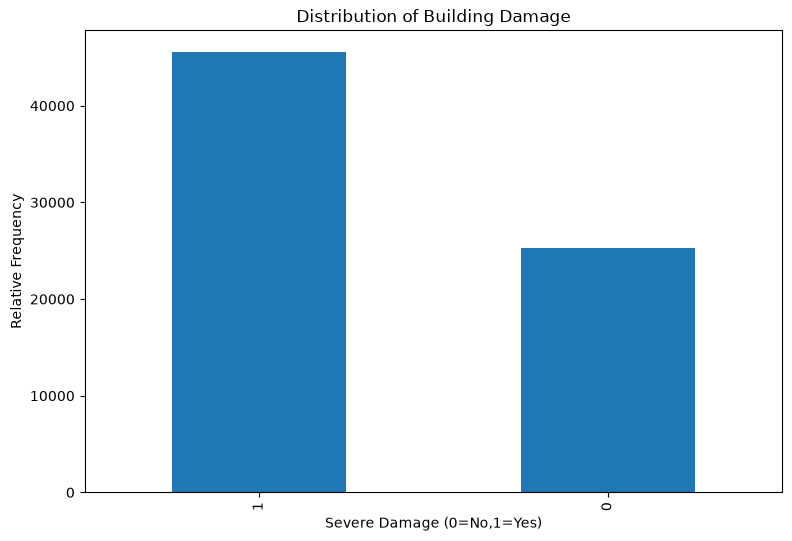

In [8]:
fig,ax=plt.subplots(figsize=(9,6))
classification_distribution.plot(kind='bar',ax=ax)
ax.set_xlabel("Severe Damage (0=No,1=Yes)")
ax.set_ylabel("Relative Frequency")
ax.set_title("Distribution of Building Damage")

plt.show()

In [9]:
45519/(25317+45519)

0.6425969845841097

In [10]:
# get categorical columns with their unique values
cat_unique_counts=df.select_dtypes('object').nunique()
cat_unique_counts

/var/folders/_r/g1b4b9xn2nn0xtb2011g11v80000gp/T/ipykernel_4459/1392998968.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_unique_counts=df.select_dtypes('object').nunique()


foundation_type      5
ground_floor_type    5
dtype: int64

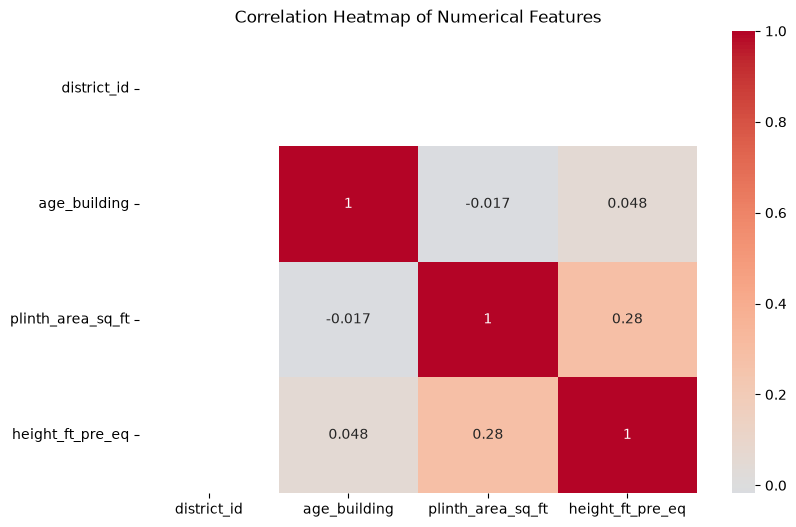

In [11]:
correlation=df.select_dtypes('number').drop(columns='severe_damage').corr()

fig,ax=plt.subplots(figsize=(9,6))
sns.heatmap(correlation,annot=True,cmap='coolwarm',center=0,ax=ax)
ax.set_title("Correlation Heatmap of Numerical Features")
plt.show()

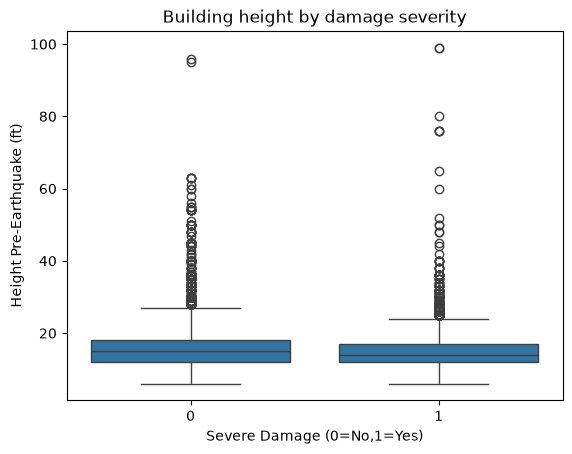

In [12]:
fig,ax=plt.subplots()
sns.boxplot(data=df,x='severe_damage',y='height_ft_pre_eq',ax=ax)
ax.set_xlabel("Severe Damage (0=No,1=Yes)")
ax.set_ylabel("Height Pre-Earthquake (ft)")
ax.set_title("Building height by damage severity")
plt.show()

In [13]:
df

,district_id,age_building,plinth_area_sq_ft,height_ft_pre_eq,foundation_type,ground_floor_type,severe_damage
building_id,,,,,,,
196856,4,18,437,15,Other,Brick/Stone,1
196880,4,3,208,13,Other,Brick/Stone,1
196909,4,2,530,14,Other,Brick/Stone,1
196926,4,15,400,16,Other,Brick/Stone,1
196931,4,11,225,16,Other,Brick/Stone,1
...,...,...,...,...,...,...,...
196598,4,50,396,16,Mud mortar-Stone/Brick,Mud,1
196629,4,50,352,15,Mud mortar-Stone/Brick,Mud,1
196637,4,1,442,18,Mud mortar-Stone/Brick,Mud,0


In [16]:
foundation_damage=pd.pivot_table(df,values="severe_damage",index='foundation_type',
                                 aggfunc='mean').sort_values(by="severe_damage",ascending=False)
foundation_damage

,severe_damage
foundation_type,
Other,0.818898
Mud mortar-Stone/Brick,0.687792
Cement-Stone/Brick,0.421908
Bamboo/Timber,0.324074
RC,0.026224


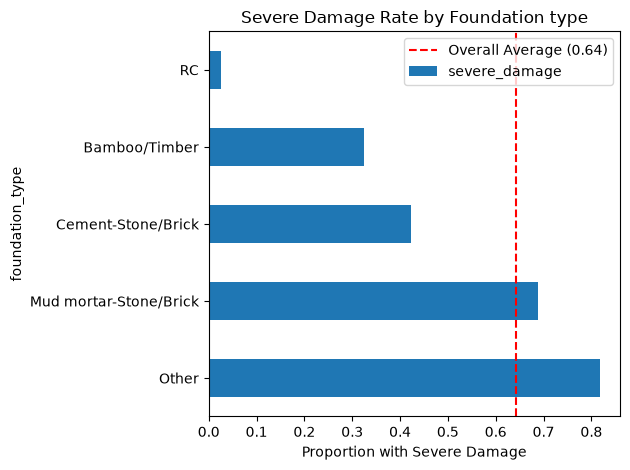

In [19]:
fig,ax=plt.subplots()
foundation_damage.plot(kind='barh',ax=ax,legend=False)
ax.set_xlabel('Proportion with Severe Damage')
ax.set_title('Severe Damage Rate by Foundation type')
ax.axvline(x=df['severe_damage'].mean(),color='red',linestyle='--',label=f"Overall Average ({df["severe_damage"].mean():.2f})")
ax.legend()
plt.tight_layout()
plt.show()

### Prepare data for machine learning

In [23]:
target="severe_damage"
features=[col for col in df.columns if col != target]

print(features)

['district_id', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'foundation_type', 'ground_floor_type']


Separate features and target

In [25]:
X=df[features]
y=df[target]



Split data into training and testing

In [26]:
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.2)

print(f"Training set: X_train {X_train.shape}, y_train {y_train.shape}")
print(f"Test set: X_test {X_test.shape}, y_test {y_test.shape}")

Training set: X_train (56668, 6), y_train (56668,)
Test set: X_test (14168, 6), y_test (14168,)


Baseline

In [30]:
baseline_acc=y_train.value_counts(normalize=True).max()
baseline_acc

np.float64(0.6415613750264699)

logistic model

In [32]:
model =Pipeline([
    ('encoder',OneHotEncoder(use_cat_names=True)),
    ('classifier',LogisticRegression(max_iter=1000))
])

model.fit(X_train,y_train)
print("Model trained successfully!")
print(f"\nModel steps: {model.steps}")

Model trained successfully!

Model steps: [('encoder', OneHotEncoder(cols=['foundation_type', 'ground_floor_type'], use_cat_names=True)), ('classifier', LogisticRegression(max_iter=1000))]


/opt/anaconda3/envs/earthquack_env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Evaluating a model

Accuracy alone is insufficient for evaluating a classifier — especially when classes are imbalanced and the costs of different error types are different.

#### Two types of errors

Here is the information organized into a clear, copyable table:

| Error Type | What Happened | Consequence |
| --- | --- | --- |
| **False Positive (FP)** | Predicted severe, actually not severe | Inspect a safe building (wasted resources, but safe) |
| **False Negative (FN)** | Predicted not severe, actually severe | Miss a damaged building (no inspection $\rightarrow$ collapse risk) |


**Accuracy** 
- Out of all predictions, how many were correct? TP+TN/total
- Uselful When your classes are reasonably balanced and you want to understand the overall correctness of your model.
- 
**Precision**
- Of all "severe" predictions, how many were actually severe?
-  Precision measures how reliable your positive predictions are. TP/(TP+FP)
-  useful when you want to minimise false positives.
-  

**Recall**
- Of all actual severe cases, how many did we catch?
- Recall measures the model's ability to identify positive cases. TP(TP+FN)

**F1 score**
- How well does the model balance precision and recall?
- F1-score is the harmonic mean of precision and recall.

1. High precision + low recall: Conservative model
    
    A conservative model is very careful about predicting severe damage.

    It only labels a building as severely damaged when it has strong evidence.

    Imagine there are 100 buildings that actually experienced severe damage.

    Your model identifies only 40 of them, but almost all its predictions are correct.
2. Low precision + high recall: Liberal model
   
    A liberal model is more willing to predict severe damage.

    It tries to identify almost every building that experienced severe damage, even if it sometimes makes incorrect predictions.

    Imagine the same 100 severely damaged buildings.

    This time, your model identifies 95 of them, but it also incorrectly flags many buildings.

**For disaster response: prefer high recall over high precision — missed buildings are more dangerous than false alarms**    





In [33]:
train_acc=accuracy_score(y_train,model.predict(X_train))
test_acc=accuracy_score(y_test,model.predict(X_test))


print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Baseline Accuracy: {baseline_acc:.4f}")
print(f"\nImprovement over baseline: {test_acc - baseline_acc:.4f}")

Training Accuracy: 0.7052
Test Accuracy: 0.7026
Baseline Accuracy: 0.6416

Improvement over baseline: 0.0610


In [34]:
y_pred=model.predict(X_test)
precision=precision_score(y_test,y_pred)
recall=recall_score(y_test,y_pred)


print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print("\nInterpretation:")
print(f"- Precision: When model predicts severe damage, it is correct {precision:.2%} of the time")
print(f"- Recall: Model identifies {recall:.2%} of all severely damaged buildings")

Precision: 0.6953
Recall: 0.9616

Interpretation:
- Precision: When model predicts severe damage, it is correct 69.53% of the time
- Recall: Model identifies 96.16% of all severely damaged buildings


### Confusion Matrix 
A confusion matrix is a table used to evaluate a classification model by comparing its predictions against the actual values.

In [35]:
cm=confusion_matrix(y_test,model.predict(X_test))
cm

array([[1143, 3862],
       [ 352, 8811]])

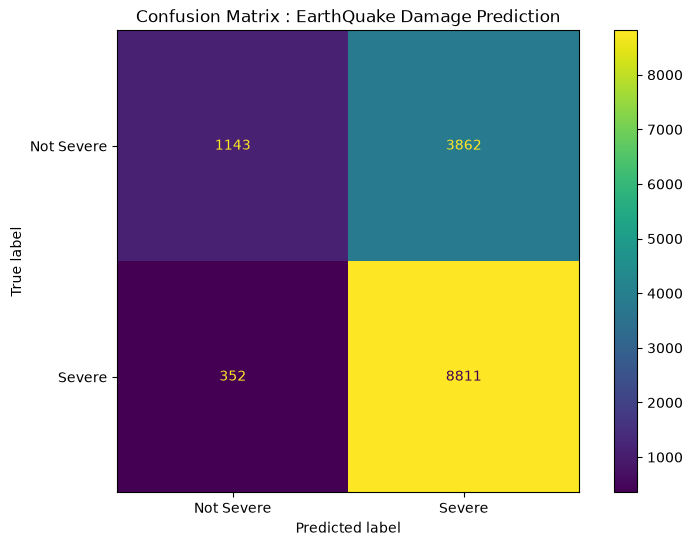

In [37]:
fig,ax=plt.subplots(figsize=(9,6))
display=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Not Severe','Severe'])
display.plot(ax=ax)
ax.set_title('Confusion Matrix : EarthQuake Damage Prediction')
plt.show()

### ROC AND AUC

ROC curve and AUC are evaluation tools used in classification problems. They help you understand how well your model distinguishes between two classes at different probability thresholds.

#### ROC curve
ROC stands for Receiver Operating Characteristic.

A ROC curve is a graph that shows the relationship between:
- True Positive Rate (TPR): The proportion of actual severe-damage buildings correctly identified. This is the same as recall.
- TPR=TP/TP/FN
- False Positive Rate (FPR): The proportion of buildings without severe damage that were incorrectly classified as severely damaged.
- FPR =FP/FP+TN


The ROC curve plots:
- X-axis = False Positive Rate
- Y-axis = True Positive Rate

![ROC](../images/Screenshot%202026-11-10%20at%2008.08.36.png)

#### How do you interpret the graph?

There are three important areas:

1. Top-left corner

This is where you want your model to be.
- High true positive rate.
- Low false positive rate.
- Identifies most severely damaged buildings without producing too many false alarms.
- 
2. Diagonal line

- This represents a random classifier.
- The model is not effectively distinguishing between the two classes.

3. Bottom-right area

This represents poor classification performance at that operating point.


#####  What is AUC?
AUC stands for Area Under the Curve.

It measures how well your model can distinguish between the positive and negative classes across different thresholds.

AUC values range from 0 to 1.






In [40]:
features_names=model.named_steps['encoder'].get_feature_names_out()
features_names

array(['district_id', 'age_building', 'plinth_area_sq_ft',
       'height_ft_pre_eq', 'foundation_type_Mud mortar-Stone/Brick',
       'foundation_type_Cement-Stone/Brick', 'foundation_type_RC',
       'foundation_type_Other', 'foundation_type_Bamboo/Timber',
       'ground_floor_type_Mud', 'ground_floor_type_RC',
       'ground_floor_type_Brick/Stone', 'ground_floor_type_Timber',
       'ground_floor_type_Other'], dtype=object)

In [42]:
coefficient=model.named_steps['classifier'].coef_[0]
coefficient

array([-1.71391347e-01,  1.16551257e-03,  1.90810586e-04,  1.28893396e-02,
        1.04805274e+00,  2.62569460e-01, -2.44107253e+00,  1.54642725e+00,
       -4.58824755e-01,  1.93776429e-01, -1.10583745e+00,  4.30691729e-01,
        6.69915540e-01, -2.31394084e-01])

In [44]:
odds_ratios=pd.Series(np.exp(coefficient),index=features_names).sort_values()
odds_ratios

foundation_type_RC                        0.087067
ground_floor_type_RC                      0.330934
foundation_type_Bamboo/Timber             0.632026
ground_floor_type_Other                   0.793427
district_id                               0.842492
plinth_area_sq_ft                         1.000191
age_building                              1.001166
height_ft_pre_eq                          1.012973
ground_floor_type_Mud                     1.213825
foundation_type_Cement-Stone/Brick        1.300267
ground_floor_type_Brick/Stone             1.538321
ground_floor_type_Timber                  1.954072
foundation_type_Mud mortar-Stone/Brick    2.852092
foundation_type_Other                     4.694667
dtype: float64

Odds ratios help us understand how a feature affects the likelihood of an outcome in a Logistic Regression model.

- Odds ratio = 2.0 for a feature → having that feature doubles the odds of severe damage
- Odds ratio = 0.5 for a feature → having that feature halves the odds of severe damage
- Odds ratio = 1.0 → no effect (that feature does not change the odds)